# 04 · Inferência com POIs — Aluguel São Paulo (capital)

**Entrada:** `data/interim/aluguel_sp_poi.parquet` (notebook 03).

**Pergunta:** quanto cada tipo de POI altera o aluguel — **descontando** o fato de que áreas nobres concentram mais serviços?

No projeto de compra, a regressão com POIs não controlava a localização: "perto de escola pública −" podia significar só "região periférica −".
Aqui cada efeito é medido em três níveis, como no notebook 02:

| Nível | Controles | O que o efeito representa |
|---|---|---|
| **Ingênuo** | nenhum | associação bruta (mistura POI + região + tamanho) |
| **+ planta** | área, tipo, banheiros, suítes, vagas, atributos do imóvel | POI para imóveis parecidos, mas em qualquer região |
| **+ planta + região** | + efeito fixo de região | **micro-localização**: o POI comparando imóveis da mesma região |

### Hipóteses (do notebook 03)
| # | Hipótese |
|---|---|
| P1 | Perto de **escola pública** o aluguel é menor, mesmo dentro da região |
| P2 | Perto de **escola privada** o aluguel é maior, mesmo dentro da região |
| P3 | O **mix escolar** (% de privadas no entorno) mede renda do entorno |
| P4 | O prêmio do **metrô** decai com a distância; metrô vale mais que trem |
| P5 | Morar **colado** à linha de trem (< 300 m) tem desconto (ruído / barreira) |
| P6 | Comércio e saúde (farmácia, supermercado, hospital) perdem quase todo o efeito ao controlar a região |
| P7 | **Parque** grande valoriza dentro da região |
| P8 | POIs **substituem** a região na previsão — e generalizam melhor para áreas não vistas |
| P9 | POIs reduzem a **autocorrelação espacial** dos resíduos |

### Roteiro
1. Setup e carga
2. Representação: "perto de" cada POI
3. Multicolinearidade (VIF)
4. Cascata: efeito de cada POI em três níveis de controle
5. Modelo conjunto (todos os POIs + planta + região)
6. Escolas públicas × privadas (P1–P3)
7. Gradiente de metrô e trem (P4, P5)
8. O efeito do metrô é igual no centro e na periferia?
9. POIs × região: explicação e generalização (P8, P9)
10. Quadro-resumo
11. Conclusões

## 1. Setup e carga

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.neighbors import BallTree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.3f}".format
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")

COR = "#2a6f97"
CINZA = "#c0c7cf"
ALFA = 0.05
RNG = 42


def achar_raiz(marcador: str = ".git") -> Path:
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
df = pd.read_parquet(ROOT / "data/interim/aluguel_sp_poi.parquet")
print(df.shape)

(22213, 146)


In [2]:
# Mesmas variáveis de controle do notebook 02
df["log_area"] = np.log(df["area"])
df["mobiliado"] = df["isFurnished"].fillna(False).astype(int)
n_reg = df["regionName"].map(df["regionName"].value_counts())
df["regiao"] = df["regionName"].where(n_reg >= 30, "Outras").astype(str)

PLANTA = "log_area + C(type, Treatment('Apartamento')) + bathrooms + suites + parkingSpaces"
ITENS = ["mobiliado", "am_ar_condicionado", "inst_piscina", "inst_academia", "am_varanda", "am_quintal"]
CONTROLES = PLANTA + " + " + " + ".join(ITENS)
CLUSTER = {"cov_type": "cluster", "cov_kwds": {"groups": pd.factorize(df["regiao"])[0]}}

resumo = []


def registrar(hip, pergunta, teste, estatistica, p, efeito, conclusao):
    resumo.append({"hipótese": hip, "pergunta": pergunta, "teste": teste,
                   "estatística": estatistica, "p": p, "efeito": efeito, "conclusão": conclusao})


def pct(b):
    return np.exp(b) - 1

## 2. Representação: "perto de" cada POI

Para ler o efeito como **"% a mais ou a menos no aluguel"** (como no projeto de compra), cada POI vira uma variável binária
`perto_<cat>` = 1 se há ao menos um POI dentro de um raio que faz sentido para aquele serviço:

| Categoria | Raio | Justificativa |
|---|---|---|
| escola pública / privada | 500 m | caminhada de criança |
| ensino superior | 1 km | |
| hospital | 1 km | |
| farmácia, conveniência | 300 m | uso cotidiano a pé |
| supermercado, polícia | 500 m | |
| metrô, trem | 800 m | ~10 min a pé (padrão de estudos de transporte) |
| parque (≥ 1 ha) | 1 km | |
| praça | 200 m | |

A versão contínua (acessibilidade) entra na seção 9, na comparação preditiva.

In [3]:
RAIOS = {
    "escola_publica": 500, "escola_privada": 500, "ensino_superior": 1000, "hospital": 1000,
    "farmacia": 300, "supermercado": 500, "conveniencia": 300, "policia": 500,
    "metro": 800, "trem": 800, "parque": 1000, "praca": 200,
}
CATS = list(RAIOS)
PERTO = [f"perto_{c}" for c in CATS]
for c, r in RAIOS.items():
    df[f"perto_{c}"] = (df[f"dist_{c}"] <= r).astype(int)

prop = df[PERTO].mean().sort_values()
prop.index = prop.index.str.replace("perto_", "")
print("% dos anúncios 'perto' de cada POI:")
print(prop.map("{:.0%}".format).to_string())

% dos anúncios 'perto' de cada POI:
trem               10%
policia            28%
conveniencia       29%
metro              31%
farmacia           35%
escola_publica     43%
hospital           56%
supermercado       62%
ensino_superior    63%
escola_privada     63%
praca              65%
parque             75%


## 3. Multicolinearidade (VIF)

POIs se concentram nas mesmas áreas. Se o VIF for alto, os efeitos individuais no modelo conjunto ficam instáveis (a soma é confiável, a divisão entre eles não).

In [4]:
X = sm.add_constant(df[PERTO + ["log_area", "bathrooms", "suites", "parkingSpaces"]].astype(float))
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                index=X.columns[1:], name="VIF").sort_values(ascending=False)
print(vif.round(2).to_string())
registrar("—", "POIs são colineares entre si?", "VIF", f"VIF máx = {vif.max():.1f}", np.nan,
          f"{vif.idxmax()} = {vif.max():.1f}",
          "Colinearidade baixa/moderada" if vif.max() < 5 else "Colinearidade relevante")

bathrooms               4.640
log_area                3.710
parkingSpaces           2.710
suites                  2.670
perto_conveniencia      1.340
perto_metro             1.340
perto_farmacia          1.310
perto_ensino_superior   1.280
perto_supermercado      1.210
perto_hospital          1.190
perto_escola_privada    1.140
perto_praca             1.130
perto_trem              1.070
perto_parque            1.050
perto_policia           1.040
perto_escola_publica    1.030


## 4. Cascata: efeito de cada POI em três níveis de controle

Cada POI entra **sozinho** (um modelo por POI e por nível). Erro-padrão agrupado por região.

In [5]:
niveis = {
    "ingênuo": "log_rent ~ {v}",
    "+ planta": f"log_rent ~ {{v}} + {CONTROLES}",
    "+ planta + região": f"log_rent ~ {{v}} + {CONTROLES} + C(regiao)",
}
linhas = []
for v in PERTO:
    for nivel, f in niveis.items():
        m = smf.ols(f.format(v=v), data=df).fit(**CLUSTER)
        b, (lo, hi) = m.params[v], m.conf_int().loc[v]
        linhas.append({"poi": v.replace("perto_", ""), "nível": nivel, "efeito": pct(b), "lo": pct(lo), "hi": pct(hi),
                       "p": m.pvalues[v]})
cascata = pd.DataFrame(linhas)
piv = cascata.pivot(index="poi", columns="nível", values="efeito")[list(niveis)]
piv["encolheu"] = 1 - piv["+ planta + região"].abs() / piv["ingênuo"].abs()
piv.sort_values("+ planta + região").map(lambda v: f"{v:+.1%}")

nível,ingênuo,+ planta,+ planta + região,encolheu
poi,,,,
escola_publica,-13.1%,-5.0%,-1.4%,+89.1%
escola_privada,+14.1%,+6.1%,-0.4%,+96.9%
hospital,+19.2%,+11.7%,+1.5%,+92.4%
supermercado,+19.6%,+11.2%,+1.7%,+91.5%
policia,+2.1%,+3.0%,+1.9%,+9.4%
farmacia,+24.8%,+12.9%,+2.0%,+92.0%
praca,+20.3%,+11.6%,+2.2%,+89.4%
parque,+12.0%,+4.2%,+2.4%,+79.9%
conveniencia,+7.5%,+11.9%,+3.3%,+55.5%


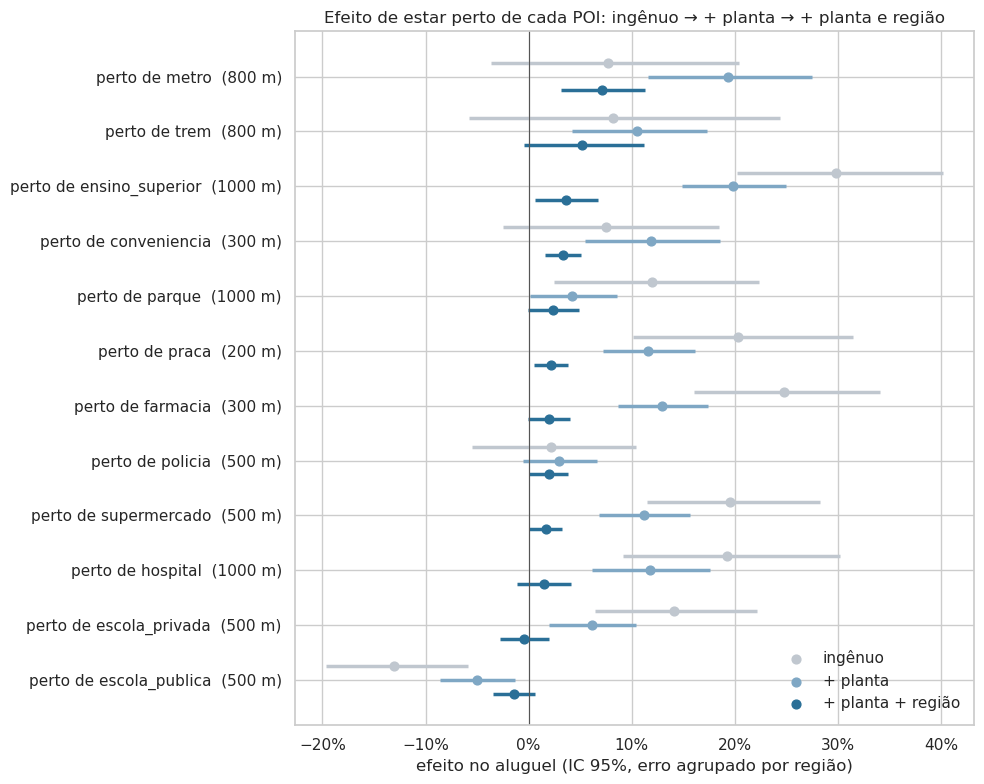

In [6]:
ordem = piv.sort_values("+ planta + região").index
cores = {"ingênuo": CINZA, "+ planta": "#7fa7c4", "+ planta + região": COR}
off = {"ingênuo": 0.25, "+ planta": 0, "+ planta + região": -0.25}

fig, ax = plt.subplots(figsize=(10, 8))
for nivel in niveis:
    sub = cascata[cascata["nível"] == nivel].set_index("poi").reindex(ordem)
    y = np.arange(len(sub)) + off[nivel]
    ax.hlines(y, sub["lo"], sub["hi"], color=cores[nivel], lw=2.5)
    ax.scatter(sub["efeito"], y, color=cores[nivel], s=40, zorder=3, label=nivel)
ax.axvline(0, color="#555", lw=0.8)
ax.set_yticks(np.arange(len(ordem)), [f"perto de {p}  ({RAIOS[p]} m)" for p in ordem])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("efeito no aluguel (IC 95%, erro agrupado por região)")
ax.set_title("Efeito de estar perto de cada POI: ingênuo → + planta → + planta e região")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

> **Como ler:** a distância entre o ponto cinza e o azul-escuro é o quanto do "efeito do POI" era, na verdade, efeito da região onde ele está.
> O ponto azul-escuro é o valor da **micro-localização** — comparar dois imóveis parecidos, na mesma região, um perto e outro longe do POI.

## 5. Modelo conjunto

Todos os POIs juntos + planta + atributos + efeito fixo de região. Correção de Holm nas 12 comparações de POI.
Este é o modelo de referência para os efeitos de POI.

In [7]:
f_conj = f"log_rent ~ {CONTROLES} + " + " + ".join(PERTO) + " + C(regiao)"
m_conj = smf.ols(f_conj, data=df).fit(**CLUSTER)

ci = m_conj.conf_int()
conj = pd.DataFrame({
    "efeito": pct(m_conj.params[PERTO]), "lo": pct(ci.loc[PERTO, 0]), "hi": pct(ci.loc[PERTO, 1]),
    "p": m_conj.pvalues[PERTO],
})
conj["p Holm"] = multipletests(conj["p"], method="holm")[1]
conj["significativo"] = conj["p Holm"] < ALFA
conj.index = conj.index.str.replace("perto_", "")
conj = conj.sort_values("efeito")

m_sem_poi = smf.ols(f"log_rent ~ {CONTROLES} + C(regiao)", data=df).fit(**CLUSTER)
wald = m_conj.wald_test(" , ".join(f"{v} = 0" for v in PERTO), scalar=True)
print(f"R² sem POIs: {m_sem_poi.rsquared:.4f}  |  com POIs: {m_conj.rsquared:.4f}  (+{m_conj.rsquared - m_sem_poi.rsquared:.4f})")
print(f"Wald conjunto (12 POIs = 0): χ² = {wald.statistic:,.1f}, p = {wald.pvalue:.1e}")
conj.assign(**{c: conj[c].map("{:+.1%}".format) for c in ["efeito", "lo", "hi"]})

R² sem POIs: 0.8319  |  com POIs: 0.8341  (+0.0022)
Wald conjunto (12 POIs = 0): χ² = 53.3, p = 3.7e-07


,efeito,lo,hi,p,p Holm,significativo
escola_publica,-1.8%,-3.6%,-0.1%,0.040,0.395,False
escola_privada,-0.6%,-2.7%,+1.5%,0.572,0.872,False
hospital,+0.9%,-1.4%,+3.2%,0.436,0.872,False
farmacia,+1.2%,-0.6%,+2.9%,0.195,0.754,False
supermercado,+1.2%,-0.6%,+3.1%,0.189,0.754,False
policia,+1.5%,-0.4%,+3.4%,0.130,0.651,False
praca,+1.5%,+0.0%,+3.0%,0.047,0.421,False
conveniencia,+1.8%,-0.1%,+3.7%,0.060,0.477,False
parque,+2.1%,-0.2%,+4.4%,0.070,0.488,False
ensino_superior,+2.8%,+0.2%,+5.4%,0.035,0.389,False


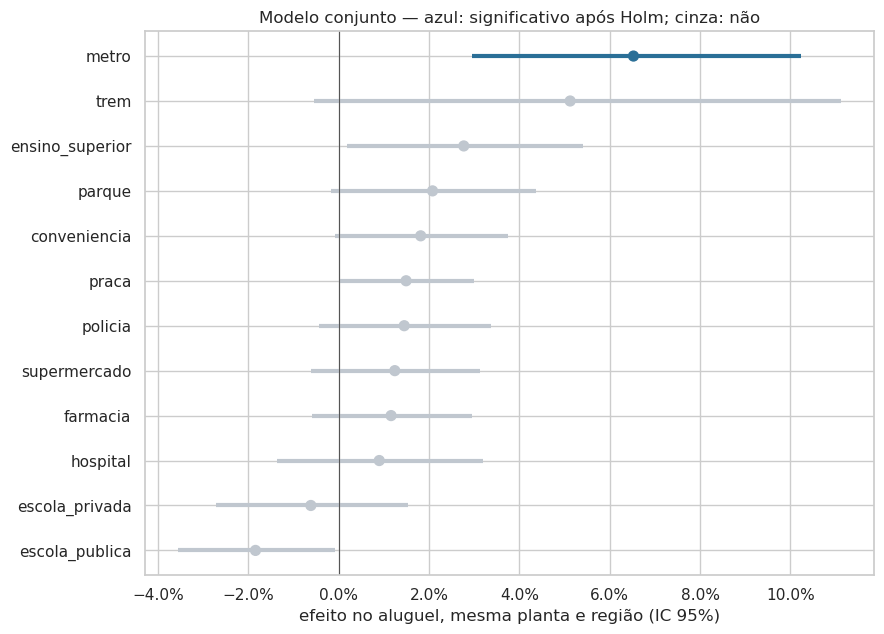

In [8]:
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(conj))
cor = np.where(conj["significativo"], COR, CINZA)
ax.hlines(y, conj["lo"], conj["hi"], color=cor, lw=3)
ax.scatter(conj["efeito"], y, color=cor, s=50, zorder=3)
ax.axvline(0, color="#555", lw=0.8)
ax.set_yticks(y, conj.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("efeito no aluguel, mesma planta e região (IC 95%)")
ax.set_title("Modelo conjunto — azul: significativo após Holm; cinza: não")
plt.tight_layout()
plt.show()

## 6. Escolas públicas × privadas (P1–P3)

1. Efeitos de `perto_escola_publica` e `perto_escola_privada` nos três níveis (da cascata) e no modelo conjunto.
2. **Mix escolar** (`pct_escola_privada_1km`): efeito de +10 p.p. de escolas privadas no entorno, com e sem região.

In [9]:
esc = cascata[cascata["poi"].isin(["escola_publica", "escola_privada"])].pivot(index="nível", columns="poi", values="efeito")
esc = esc.reindex(list(niveis))
esc.loc["modelo conjunto"] = conj.loc[["escola_privada", "escola_publica"], "efeito"].values
print(esc.map("{:+.1%}".format).to_string())

dmix = df.dropna(subset=["pct_escola_privada_1km"]).copy()
dmix["mix10"] = dmix["pct_escola_privada_1km"] * 10          # coeficiente = efeito de +10 p.p.
cl_mix = {"cov_type": "cluster", "cov_kwds": {"groups": pd.factorize(dmix["regiao"])[0]}}
mix = {}
for nome, f in {"ingênuo": "log_rent ~ mix10", "+ planta": f"log_rent ~ mix10 + {CONTROLES}",
                "+ planta + região": f"log_rent ~ mix10 + {CONTROLES} + C(regiao)"}.items():
    m = smf.ols(f, data=dmix).fit(**cl_mix)
    mix[nome] = (pct(m.params["mix10"]), *pct(m.conf_int().loc["mix10"]), m.pvalues["mix10"])
mix = pd.DataFrame(mix, index=["efeito", "lo", "hi", "p"]).T
print("\nEfeito de +10 p.p. de escolas privadas a até 1 km:")
print(mix.assign(**{c: mix[c].map("{:+.2%}".format) for c in ["efeito", "lo", "hi"]}).to_string())

poi               escola_privada escola_publica
nível                                          
ingênuo                   +14.1%         -13.1%
+ planta                   +6.1%          -5.0%
+ planta + região          -0.4%          -1.4%
modelo conjunto            -0.6%          -1.8%

Efeito de +10 p.p. de escolas privadas a até 1 km:
                   efeito      lo      hi     p
ingênuo            +6.21%  +4.60%  +7.84% 0.000
+ planta           +3.10%  +2.15%  +4.06% 0.000
+ planta + região  +0.98%  +0.32%  +1.65% 0.004


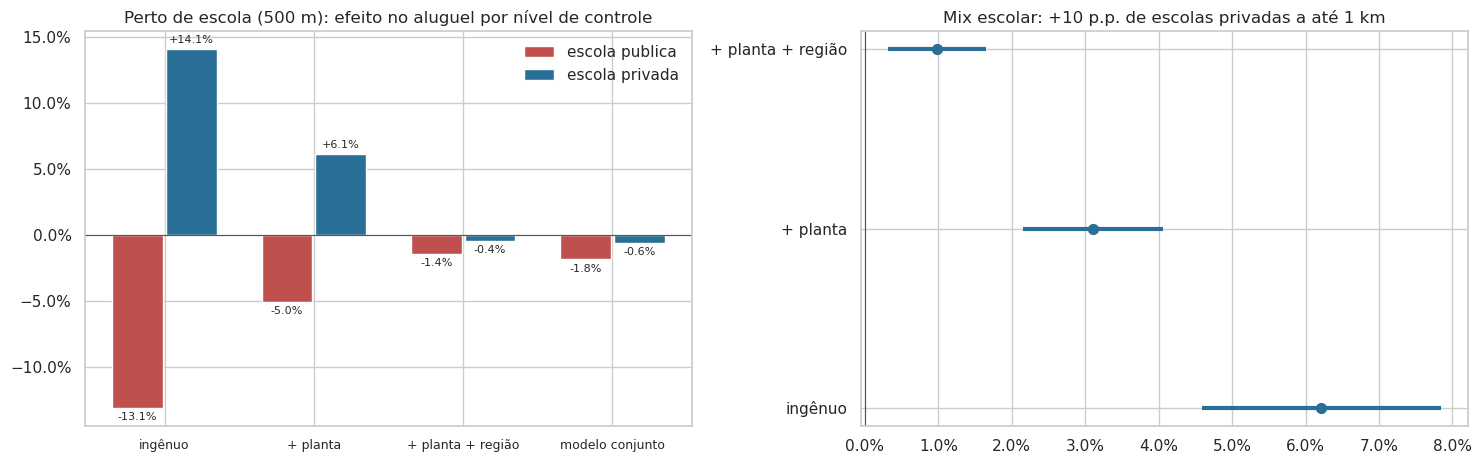

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(esc))
for (c, cor), d in zip([("escola_publica", "#c0504d"), ("escola_privada", COR)], [-0.18, 0.18]):
    axes[0].bar(x + d, esc[c], width=0.34, color=cor, label=c.replace("_", " "))
    for xi, v in zip(x, esc[c]):
        axes[0].annotate(f"{v:+.1%}", (xi + d, v), ha="center", va="bottom" if v >= 0 else "top",
                         xytext=(0, 3 if v >= 0 else -3), textcoords="offset points", fontsize=8)
axes[0].axhline(0, color="#555", lw=0.8)
axes[0].set_xticks(x, esc.index, fontsize=9)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_title("Perto de escola (500 m): efeito no aluguel por nível de controle")
axes[0].legend(frameon=False)

y = np.arange(len(mix))
axes[1].hlines(y, mix["lo"], mix["hi"], color=COR, lw=3)
axes[1].scatter(mix["efeito"], y, color=COR, s=50, zorder=3)
axes[1].axvline(0, color="#555", lw=0.8)
axes[1].set_yticks(y, mix.index)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
axes[1].set_title("Mix escolar: +10 p.p. de escolas privadas a até 1 km")
plt.tight_layout()
plt.show()

for hip, c, perg in [("P1", "escola_publica", "Perto de escola pública reduz o aluguel?"),
                     ("P2", "escola_privada", "Perto de escola privada aumenta o aluguel?")]:
    r = conj.loc[c]
    registrar(hip, perg, "OLS conjunto + FE região (cluster, Holm)", f"{r['efeito']:+.1%} [{r['lo']:+.1%}; {r['hi']:+.1%}]",
              r["p Holm"], f"ingênuo {esc.loc['ingênuo', c]:+.1%} → controlado {r['efeito']:+.1%}",
              "Efeito controlado" if r["significativo"] else "Efeito some ao controlar a região")
r = mix.loc["+ planta + região"]
registrar("P3", "Mix escolar mede renda do entorno?", "OLS + FE região (cluster)", f"{r['efeito']:+.2%} por +10 p.p.", r["p"],
          f"ingênuo {mix.loc['ingênuo', 'efeito']:+.1%} → controlado {r['efeito']:+.2%} por +10 p.p.",
          "Associação forte entre regiões; " + ("persiste dentro da região" if r["p"] < ALFA else "some dentro da região"))

## 7. Gradiente de metrô e trem (P4, P5)

Em vez de "perto / longe", faixas de distância (referência: > 2 km) no modelo com planta e região.
Mostra **como o prêmio decai** e se há desconto colado à linha de trem.

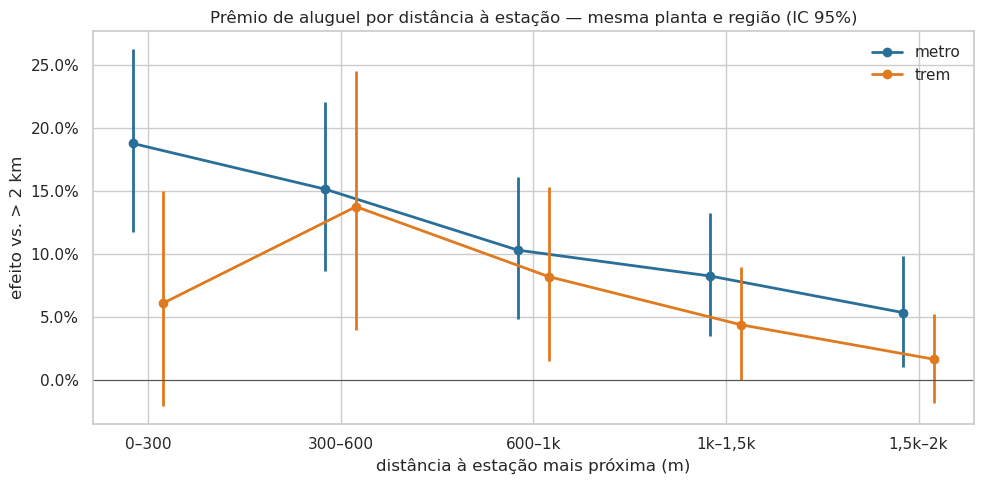

,modo,faixa,efeito,lo,hi,p,n
0,metro,0–300,+18.8%,+11.8%,+26.3%,0.000,1856
1,metro,300–600,+15.2%,+8.7%,+22.1%,0.000,3669
2,metro,600–1k,+10.3%,+4.8%,+16.1%,0.000,2559
3,metro,"1k–1,5k",+8.3%,+3.5%,+13.3%,0.001,2819
4,metro,"1,5k–2k",+5.4%,+1.0%,+9.9%,0.015,2468
5,trem,0–300,+6.1%,-2.1%,+15.0%,0.146,345
6,trem,300–600,+13.8%,+4.0%,+24.6%,0.005,886
7,trem,600–1k,+8.2%,+1.5%,+15.4%,0.015,1906
8,trem,"1k–1,5k",+4.4%,+0.0%,+9.0%,0.048,2394
9,trem,"1,5k–2k",+1.7%,-1.8%,+5.2%,0.347,2381


In [11]:
BINS = [0, 300, 600, 1000, 1500, 2000, np.inf]
ROT = ["0–300", "300–600", "600–1k", "1k–1,5k", "1,5k–2k", "> 2k"]
for c in ["metro", "trem"]:
    df[f"faixa_{c}"] = pd.cut(df[f"dist_{c}"], BINS, labels=ROT, right=False).astype(str)

m_grad = smf.ols(f"log_rent ~ C(faixa_metro, Treatment('> 2k')) + C(faixa_trem, Treatment('> 2k')) + {CONTROLES} + C(regiao)",
                 data=df).fit(**CLUSTER)
ci = m_grad.conf_int()
grad = []
for c in ["metro", "trem"]:
    for r in ROT[:-1]:
        t = f"C(faixa_{c}, Treatment('> 2k'))[T.{r}]"
        grad.append({"modo": c, "faixa": r, "efeito": pct(m_grad.params[t]), "lo": pct(ci.loc[t, 0]),
                     "hi": pct(ci.loc[t, 1]), "p": m_grad.pvalues[t], "n": (df[f"faixa_{c}"] == r).sum()})
grad = pd.DataFrame(grad)

fig, ax = plt.subplots(figsize=(10, 5))
for c, cor, d in [("metro", COR, -0.08), ("trem", "#e07a1f", 0.08)]:
    g = grad[grad["modo"] == c]
    x = np.arange(len(g)) + d
    ax.vlines(x, g["lo"], g["hi"], color=cor, lw=2)
    ax.plot(x, g["efeito"], marker="o", color=cor, lw=2, label=c)
ax.axhline(0, color="#555", lw=0.8)
ax.set_xticks(range(len(ROT) - 1), ROT[:-1])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("distância à estação mais próxima (m)")
ax.set_ylabel("efeito vs. > 2 km")
ax.set_title("Prêmio de aluguel por distância à estação — mesma planta e região (IC 95%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

grad.assign(**{c: grad[c].map("{:+.1%}".format) for c in ["efeito", "lo", "hi"]})

In [12]:
gm = grad[grad["modo"] == "metro"].set_index("faixa")
gt = grad[grad["modo"] == "trem"].set_index("faixa")
decai = gm.loc["0–300", "efeito"] > gm.loc["1k–1,5k", "efeito"]
registrar("P4", "Prêmio do metrô decai com a distância?", "OLS faixas + FE região (cluster)",
          f"0–300 m: {gm.loc['0–300', 'efeito']:+.1%}", gm.loc["0–300", "p"],
          f"metrô 0–300 {gm.loc['0–300', 'efeito']:+.1%} → 1–1,5k {gm.loc['1k–1,5k', 'efeito']:+.1%}; trem 300–600 {gt.loc['300–600', 'efeito']:+.1%}",
          "Gradiente confirmado" if decai and gm.loc["0–300", "p"] < ALFA else "Sem gradiente claro")
colado = gt.loc["0–300"]
registrar("P5", "Colado ao trem (< 300 m) tem desconto?", "OLS faixas + FE região (cluster)",
          f"{colado['efeito']:+.1%} [{colado['lo']:+.1%}; {colado['hi']:+.1%}]", colado["p"],
          f"0–300 m {colado['efeito']:+.1%} vs. 300–600 m {gt.loc['300–600', 'efeito']:+.1%}",
          "Há desconto colado à linha" if colado["efeito"] < gt.loc["300–600", "efeito"] and colado["p"] < ALFA
          else "Sem evidência de desconto")

## 8. O efeito do metrô é igual no centro e na periferia?

Interação `perto_metro × periferia` (periferia = mais de 10 km da Sé). Hipótese: onde há pouca alternativa de transporte, a estação vale mais.

In [13]:
df["periferia"] = (df["dist_centro_km"] > 10).astype(int)
m_int = smf.ols(f"log_rent ~ perto_metro * periferia + {CONTROLES} + C(regiao)", data=df).fit(**CLUSTER)
b_centro = m_int.params["perto_metro"]
b_perif = b_centro + m_int.params["perto_metro:periferia"]
p_int = m_int.pvalues["perto_metro:periferia"]
n_perif = df.loc[df["periferia"] == 1, "perto_metro"].sum()
print(f"Perto de metrô — até 10 km do centro: {pct(b_centro):+.1%}")
print(f"Perto de metrô — periferia (> 10 km): {pct(b_perif):+.1%}   (n perto de metrô na periferia = {n_perif:,})")
print(f"Interação: p = {p_int:.3f}")
registrar("—", "Metrô vale mais na periferia?", "OLS com interação + FE região", f"p (interação) = {p_int:.3f}", p_int,
          f"centro {pct(b_centro):+.1%}; periferia {pct(b_perif):+.1%}",
          "Efeito difere" if p_int < ALFA else "Sem diferença detectável")

Perto de metrô — até 10 km do centro: +6.5%
Perto de metrô — periferia (> 10 km): +6.6%   (n perto de metrô na periferia = 1,266)
Interação: p = 0.966


## 9. POIs × região: explicação e generalização (P8, P9)

Quatro modelos lineares em `log(rent)`:

| Modelo | Variáveis |
|---|---|
| A | planta + atributos |
| B | A + **POIs** (log da distância + acessibilidade, 12 categorias) |
| C | A + **região** (efeito fixo) |
| D | A + região + POIs |

Duas validações cruzadas (5 folds):
- **Aleatória** — imóveis do teste têm vizinhos no treino.
- **Espacial** — 30 clusters de lat/lon (KMeans); o fold de teste é uma área inteira que o modelo **nunca viu**. É o cenário de prever um bairro novo, e o teste honesto de generalização.

Métricas: R² em log e **MAE em R$** (previsão convertida de volta com `exp`).

In [14]:
POI_NUM = [f"logdist_{c}" for c in CATS] + [f"logacess_{c}" for c in CATS]
for c in CATS:
    df[f"logdist_{c}"] = np.log(df[f"dist_{c}"] + 50)
    df[f"logacess_{c}"] = np.log1p(df[f"acess_{c}"])

BASE_NUM = ["log_area", "bathrooms", "suites", "parkingSpaces"] + ITENS
MODELOS = {
    "A · planta": (BASE_NUM, ["type"]),
    "B · planta + POIs": (BASE_NUM + POI_NUM, ["type"]),
    "C · planta + região": (BASE_NUM, ["type", "regiao"]),
    "D · planta + região + POIs": (BASE_NUM + POI_NUM, ["type", "regiao"]),
}

y = df["log_rent"].values
grupos_esp = KMeans(n_clusters=30, n_init=10, random_state=RNG).fit_predict(np.radians(df[["lat", "lon"]]))
CVS = {
    "aleatória": (KFold(5, shuffle=True, random_state=RNG), None),
    "espacial": (GroupKFold(5), grupos_esp),
}


def pipeline(num, cat):
    pre = ColumnTransformer([("num", "passthrough", num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", drop=None), cat)])
    return make_pipeline(pre, LinearRegression())


linhas = []
for nome, (num, cat) in MODELOS.items():
    X = df[num + cat]
    for cv_nome, (cv, g) in CVS.items():
        pred = cross_val_predict(pipeline(num, cat), X, y, cv=cv, groups=g)
        linhas.append({"modelo": nome, "validação": cv_nome,
                       "R² (log)": 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                       "MAE (R$)": np.mean(np.abs(np.exp(y) - np.exp(pred))),
                       "MAPE": np.median(np.abs(np.exp(pred) / np.exp(y) - 1))})
cv_res = pd.DataFrame(linhas)
cv_res.pivot(index="modelo", columns="validação", values=["R² (log)", "MAE (R$)", "MAPE"]).round(3)

R² (log)           MAE (R$)                MAPE  \
validação                  aleatória espacial aleatória  espacial aleatória   
modelo                                                                        
A · planta                     0.748    0.743 1,214.177 1,223.653     0.215   
B · planta + POIs              0.814    0.793 1,061.288 1,108.660     0.180   
C · planta + região            0.829    0.745 1,020.912 1,202.921     0.168   
D · planta + região + POIs     0.838    0.792   997.876 1,114.248     0.164   

                                     
validação                  espacial  
modelo                               
A · planta                    0.218  
B · planta + POIs             0.190  
C · planta + região           0.209  
D · planta + região + POIs    0.186

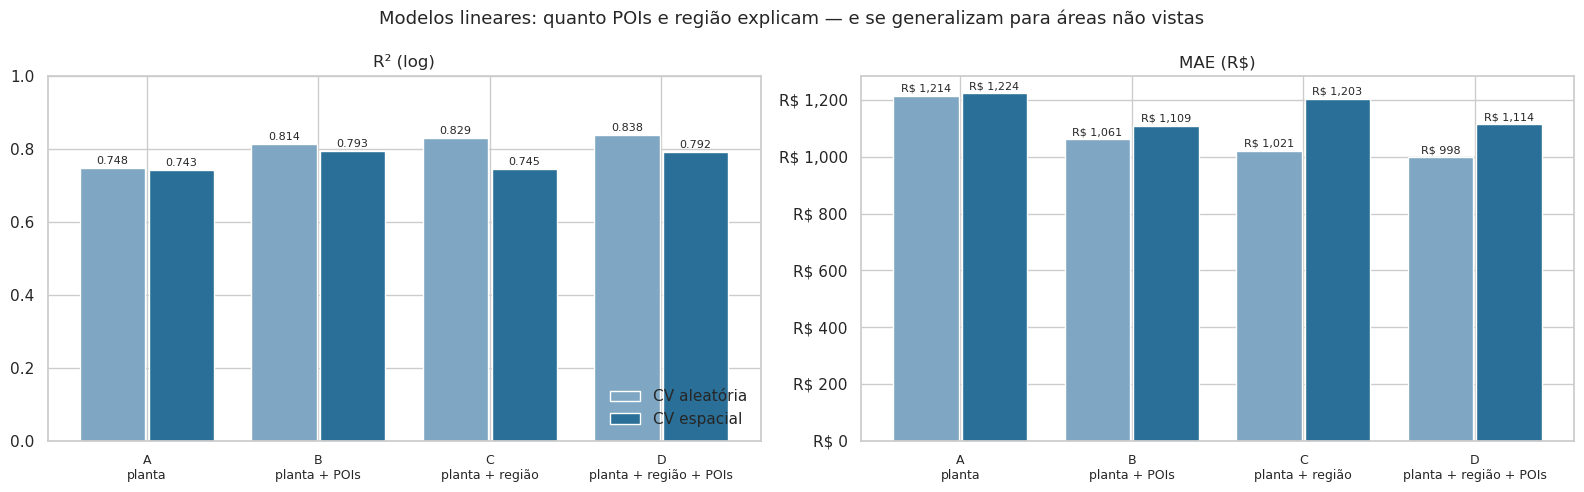

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
mods = list(MODELOS)
x = np.arange(len(mods))
for ax, met, fmt in [(axes[0], "R² (log)", "{:.3f}"), (axes[1], "MAE (R$)", "R$ {:,.0f}")]:
    for cv_nome, cor, d in [("aleatória", "#7fa7c4", -0.2), ("espacial", COR, 0.2)]:
        v = cv_res[cv_res["validação"] == cv_nome].set_index("modelo").loc[mods, met]
        ax.bar(x + d, v, width=0.38, color=cor, label=f"CV {cv_nome}")
        for xi, vi in zip(x, v):
            ax.annotate(fmt.format(vi), (xi + d, vi), ha="center", xytext=(0, 3), textcoords="offset points", fontsize=8)
    ax.set_xticks(x, [m.replace(" · ", "\n") for m in mods], fontsize=9)
    ax.set_title(met)
axes[0].set_ylim(0, 1)
axes[0].legend(frameon=False, loc="lower right")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("R$ {x:,.0f}"))
fig.suptitle("Modelos lineares: quanto POIs e região explicam — e se generalizam para áreas não vistas", fontsize=13)
plt.tight_layout()
plt.show()

In [16]:
def autocorr_espacial(res: np.ndarray, k: int = 10) -> float:
    coords = np.radians(df[["lat", "lon"]].values)
    _, ind = BallTree(coords, metric="haversine").query(coords, k=k + 1)
    return np.corrcoef(res, res[ind[:, 1:]].mean(axis=1))[0, 1]


ac = {}
for nome, (num, cat) in MODELOS.items():
    m = pipeline(num, cat).fit(df[num + cat], y)
    ac[nome] = autocorr_espacial(y - m.predict(df[num + cat]))
ac = pd.Series(ac)
print("Correlação do resíduo com a média dos 10 vizinhos:")
print(ac.round(3).to_string())

esp = cv_res[cv_res["validação"] == "espacial"].set_index("modelo")
ale = cv_res[cv_res["validação"] == "aleatória"].set_index("modelo")
registrar("P8", "POIs substituem a região na previsão?", "CV aleatória e espacial (OLS)",
          f"R² espacial: B {esp.loc['B · planta + POIs', 'R² (log)']:.3f} × C {esp.loc['C · planta + região', 'R² (log)']:.3f}",
          np.nan,
          f"MAE espacial: B R$ {esp.loc['B · planta + POIs', 'MAE (R$)']:,.0f} × C R$ {esp.loc['C · planta + região', 'MAE (R$)']:,.0f}; "
          f"D R$ {esp.loc['D · planta + região + POIs', 'MAE (R$)']:,.0f}",
          "POIs generalizam melhor que região" if esp.loc["B · planta + POIs", "R² (log)"] > esp.loc["C · planta + região", "R² (log)"]
          else "Região ainda supera POIs")
registrar("P9", "POIs reduzem a autocorrelação espacial?", "corr. resíduo × 10 vizinhos",
          f"C {ac['C · planta + região']:.2f} → D {ac['D · planta + região + POIs']:.2f}", np.nan,
          f"A {ac['A · planta']:.2f}; B {ac['B · planta + POIs']:.2f}; C {ac['C · planta + região']:.2f}; D {ac['D · planta + região + POIs']:.2f}",
          "Reduzem, mas não eliminam" if ac["D · planta + região + POIs"] < ac["C · planta + região"] else "Não reduzem")

Correlação do resíduo com a média dos 10 vizinhos:
A · planta                   0.559
B · planta + POIs            0.444
C · planta + região          0.341
D · planta + região + POIs   0.293


In [17]:
# P6, P7 a partir do modelo conjunto
for hip, cs, perg in [("P6", ["farmacia", "supermercado", "hospital"], "Comércio e saúde perdem o efeito ao controlar a região?"),
                      ("P7", ["parque"], "Parque grande valoriza dentro da região?")]:
    ing = cascata[(cascata["nível"] == "ingênuo") & cascata["poi"].isin(cs)].set_index("poi")["efeito"].reindex(cs)
    ctl = conj.loc[cs]
    registrar(hip, perg, "Cascata + OLS conjunto (Holm)",
              "; ".join(f"{c} {ctl.loc[c, 'efeito']:+.1%}" for c in cs),
              ctl["p Holm"].min(),
              "; ".join(f"{c}: {ing[c]:+.0%} → {ctl.loc[c, 'efeito']:+.1%}" for c in cs),
              ("Sim, efeito some/encolhe" if hip == "P6" and (ctl["efeito"].abs() < ing.abs() / 3).all()
               else "Valoriza" if hip == "P7" and ctl.loc["parque", "significativo"] and ctl.loc["parque", "efeito"] > 0
               else "Parcialmente / não"))

## 10. Quadro-resumo

In [18]:
quadro = pd.DataFrame(resumo)
quadro["p"] = quadro["p"].map(lambda p: "—" if pd.isna(p) else ("< 0,001" if p < 0.001 else f"{p:.3f}"))
with pd.option_context("display.max_colwidth", 90):
    display(quadro.set_index("hipótese"))

OUT_DIR = ROOT / "results/inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)
quadro.to_csv(OUT_DIR / "aluguel_poi_hipoteses.csv", index=False)
conj.to_csv(OUT_DIR / "aluguel_poi_efeitos.csv")
cv_res.to_csv(OUT_DIR / "aluguel_poi_cv_linear.csv", index=False)
print(f"Salvo em {OUT_DIR.relative_to(ROOT)}/")

,pergunta,teste,estatística,p,efeito,conclusão
hipótese,,,,,,
—,POIs são colineares entre si?,VIF,VIF máx = 4.6,—,bathrooms = 4.6,Colinearidade baixa/moderada
P1,Perto de escola pública reduz o aluguel?,"OLS conjunto + FE região (cluster, Holm)",-1.8% [-3.6%; -0.1%],0.395,ingênuo -13.1% → controlado -1.8%,Efeito some ao controlar a região
P2,Perto de escola privada aumenta o aluguel?,"OLS conjunto + FE região (cluster, Holm)",-0.6% [-2.7%; +1.5%],0.872,ingênuo +14.1% → controlado -0.6%,Efeito some ao controlar a região
P3,Mix escolar mede renda do entorno?,OLS + FE região (cluster),+0.98% por +10 p.p.,0.004,ingênuo +6.2% → controlado +0.98% por +10 p.p.,Associação forte entre regiões; persiste dentro da região
P4,Prêmio do metrô decai com a distância?,OLS faixas + FE região (cluster),0–300 m: +18.8%,"< 0,001","metrô 0–300 +18.8% → 1–1,5k +8.3%; trem 300–600 +13.8%",Gradiente confirmado
P5,Colado ao trem (< 300 m) tem desconto?,OLS faixas + FE região (cluster),+6.1% [-2.1%; +15.0%],0.146,0–300 m +6.1% vs. 300–600 m +13.8%,Sem evidência de desconto
—,Metrô vale mais na periferia?,OLS com interação + FE região,p (interação) = 0.966,0.966,centro +6.5%; periferia +6.6%,Sem diferença detectável
P8,POIs substituem a região na previsão?,CV aleatória e espacial (OLS),R² espacial: B 0.793 × C 0.745,—,"MAE espacial: B R$ 1,109 × C R$ 1,203; D R$ 1,114",POIs generalizam melhor que região
P9,POIs reduzem a autocorrelação espacial?,corr. resíduo × 10 vizinhos,C 0.34 → D 0.29,—,A 0.56; B 0.44; C 0.34; D 0.29,"Reduzem, mas não eliminam"


Salvo em results/inference/


## 11. Conclusões

### 1. Dentro da mesma região, quase todo efeito de POI desaparece — o metrô é a exceção

| POI (raio) | Ingênuo | + planta | + planta + região | Quanto do efeito era região/tamanho |
|---|---|---|---|---|
| **Metrô (800 m)** | +8% | +19% | **+7%** (único significativo após Holm no modelo conjunto: +6,5%) | — |
| Ensino superior (1 km) | +30% | +20% | +4% | 88% |
| Farmácia (300 m) | +25% | +13% | +2% | 92% |
| Supermercado (500 m) | +20% | +11% | +2% | 92% |
| Hospital (1 km) | +19% | +12% | +1,5% | 92% |
| Escola privada (500 m) | +14% | +6% | −0,4% | 97% |
| **Escola pública (500 m)** | **−13%** | −5% | **−1,4%** | 89% |
| Parque ≥ 1 ha (1 km) | +12% | +4% | +2% | 80% |

- Os POIs **são** a região: áreas nobres têm mais farmácias, hospitais, faculdades e escolas privadas. Quando o modelo compara imóveis da mesma região, sobra pouco efeito próprio.
- No modelo conjunto (12 POIs + planta + região), os POIs adicionam só +0,002 de R² ao modelo com região. **Apenas o metrô** mantém efeito após a correção de Holm.

### 2. Escolas: o efeito do projeto de compra era a região
- Perto de escola pública: −13% ingênuo → **−1,4% a −1,8%** controlando planta e região, não significativo após Holm.
- Perto de escola privada: +14% ingênuo → **≈ 0%** controlado.
- O mesmo padrão provavelmente explica os −10% / +4% do projeto de compra, cuja regressão não tinha efeito de bairro: escola pública indicava **periferia**, não um efeito da escola.
- O **mix escolar** é o que sobra com sinal: +10 p.p. de escolas privadas no entorno → +6,2% ingênuo e **+1,0%** dentro da região (p = 0,004). É um termômetro fino de renda do quarteirão, útil como feature.

### 3. Metrô: prêmio real e com gradiente
- Comparando imóveis da mesma região: **+19%** a até 300 m da estação, +15% a 300–600 m, +10% a 600 m–1 km, +8% a 1–1,5 km e +5% a 1,5–2 km (referência: > 2 km).
- O trem tem prêmio menor (pico de +14% a 300–600 m). Colado à linha (0–300 m) o efeito é +6% com IC largo (n = 345) — **sem evidência estatística** de desconto, embora a curva sugira.
- O prêmio do metrô é o **mesmo** no centro e na periferia (+6,5% × +6,6%, p = 0,97).

### 4. O resultado mais importante para produção: POIs generalizam, região não

| Modelo linear | R² CV aleatória | R² CV espacial | MAE espacial |
|---|---|---|---|
| A · planta | 0,748 | 0,743 | R$ 1.224 |
| B · planta + POIs | 0,814 | **0,793** | **R$ 1.109** |
| C · planta + região | **0,829** | 0,745 | R$ 1.203 |
| D · planta + região + POIs | 0,838 | 0,792 | R$ 1.114 |

- Na CV aleatória, a **região** ganha. Mas quando o modelo precisa prever uma **área que nunca viu** (CV espacial), o efeito de região não ajuda (C ≈ A), enquanto os POIs mantêm quase todo o ganho (B: 0,814 → 0,793).
- Ou seja: a região **memoriza** o preço de áreas conhecidas; os POIs **descrevem** a área e transferem para lugares novos.
- POIs também reduzem a autocorrelação espacial do resíduo (A 0,56 → B 0,44; C 0,34 → D 0,29), mas não a eliminam — ainda há micro-localização não capturada.

### Implicações para o feature engineering e a modelagem
1. **Usar POIs + região juntos** (modelo D): melhor nas duas validações. Os POIs são o "seguro" para regiões com poucos anúncios ou novas.
2. **Representação contínua** (log da distância + acessibilidade) em vez de flags binárias; o metrô pede faixas ou modelo de árvore pelo gradiente não linear.
3. **Features prioritárias:** distância ao metrô, acessibilidade de comércio/saúde/ensino superior (ou o índice PC1), mix escolar. Escola pública/privada isoladas, polícia e parque têm baixa prioridade.
4. **Validação espacial obrigatória** no notebook de modelagem — a CV aleatória superestima o efeito da região em ~0,08 de R².
5. **Régua atualizada:** o melhor linear (D) erra em mediana 16–19% do aluguel. O modelo de ML precisa superar isso **na CV espacial**.

### Limitações
- Cobertura desigual do OSM (melhor mapeado nas áreas caras) e subcontagem de escolas públicas. Fontes oficiais (Censo Escolar/INEP, GeoSampa) são uma melhoria futura.
- Efeitos são associações controladas, não causais: um imóvel perto do metrô pode ser diferente em atributos não observados (andar, idade do prédio).